# Ch 12 검색을 그래프로 잇기

**이 노트북에서 할 일**

1. Ch 12가 남긴 문서 청크와 통합 기록에서 질문 하나를 가져옵니다.
2. 거리 검색과 낱말 검색과 순위 합치기와 답 쓰기를 노드 다섯으로 나눠 잇습니다.
3. 그래프가 그린 구조와 실행 흔적 칸을 견줍니다.
4. 가중치 한 자리만 바꿔 다시 실행하고 두 결과를 나란히 봅니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 다섯 번입니다(임베딩 세 번과 답을 쓰는 모델 두 번).
예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 Ch 12 파일 두 개이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangGraph 1.2.11과 LangChain 1.4.0을 설치합니다.
Ch 12 임베딩에 쓰는 langchain-openai 1.6.1도 함께 설치합니다.
낱말 검색에 쓰는 kiwipiepy 0.23.2와 rank-bm25 0.2.2도 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
Ch 12 자료를 읽고 함수를 준비한 뒤 노드 다섯을 만들어 붙이는 자리입니다.
9절과 10절은 같은 그래프에 넣는 값 하나만 바꿔 보는 자리입니다.
11절은 두 실행을 기록 한 줄씩으로 만들어 표로 견주는 자리입니다.
준비부터 끝까지 함께 실행하고 실습 시간에 다시 읽습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

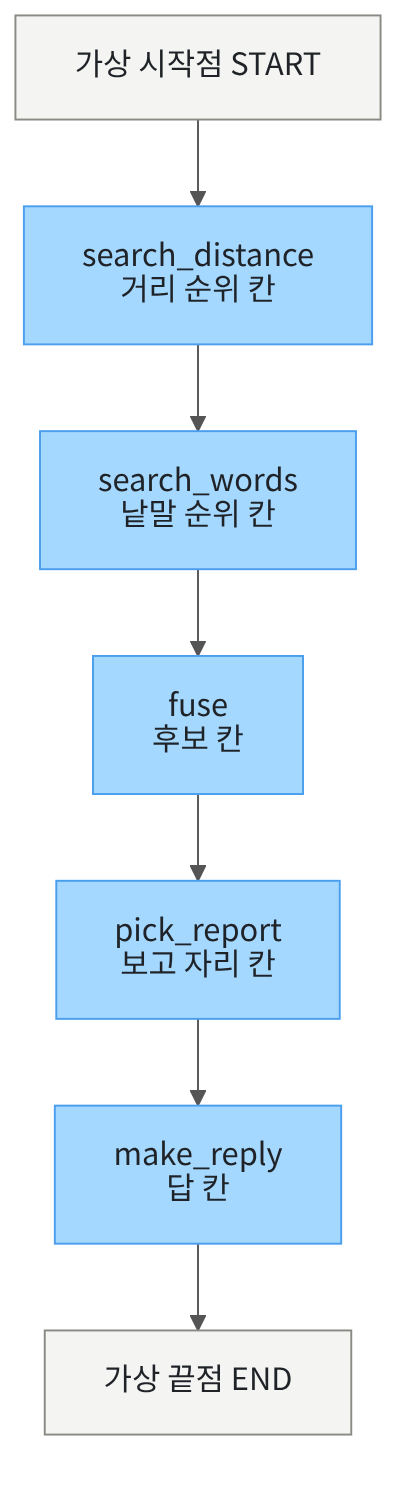

맨 위 회색 상자가 입력이 들어오는 자리입니다.
그 아래 파란 상자 다섯이 이 절에서 만들 노드입니다.
상자마다 그 노드가 채우는 칸 이름이 함께 적혀 있습니다.
맨 아래 회색 상자에서 한 줄기가 끝납니다.

## 1. 준비

첫 셀은 패키지 여섯 개를 설치하고 설치된 판 번호를 출력합니다.
01~06절보다 설치가 길어 몇 분이 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 판 번호 여섯 줄이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 열두 개를 불러옵니다.
앞의 일곱은 01~06절에서 쓴 것과 같습니다.
뒤의 다섯은 Ch 9~12에서 쓴 검색 도구입니다.

In [2]:
# 자료 읽기·제곱근·경로 확인과 그래프 이름과 Ch 12 검색 도구를 불러옵니다
import json
import math
import operator
import os
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from kiwipiepy import Kiwi
from rank_bm25 import BM25Okapi
from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model

print("이 챕터에서 처음 부르는 이름:", "OpenAIEmbeddings", "BM25Okapi", "Kiwi")

이 챕터에서 처음 부르는 이름: OpenAIEmbeddings BM25Okapi Kiwi


**결과 읽기** — 출력 줄에 이 챕터에서 처음 부르는 이름 셋이 보입니다.
임베딩을 만드는 `OpenAIEmbeddings`와 낱말 겹침 점수를 내는 `BM25Okapi`와 형태소 분석기 `Kiwi`입니다.
셋 다 Ch 12에서 쓴 것과 같은 이름입니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


답을 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-19에 이 모델로 실행한 결과입니다.
temperature 값이 0이어도 답 문장이 매번 같다고 보장하지 않습니다.

## 3. Ch 12 자료 읽기

이 절은 Ch 12가 만든 문서 청크와 통합 기록을 읽습니다.
두 파일 모두 읽기만 하고 고치지 않습니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄 `고른 경로` 뒤에 점 하나나 위로 올라가는 경로가 보입니다.
Ch 10~12에서 쓴 경로 찾기와 같은 코드입니다.
후보 셋 가운데 Ch 12 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 Ch 12 파일 두 개를 읽습니다.

In [6]:
# Ch 12가 남긴 문서 파일과 통합 기록 파일을 읽습니다(읽기만 하고 고치지 않습니다)
chapter12_path = root_path + "/labs/part3/ch12-retrieval-tuning"
with open(chapter12_path + "/data/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(chapter12_path + "/runs/advanced-continuity-integrated-result.json", encoding="utf-8") as file:
    prior_record = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))

부모 문서 수: 6
문서 청크 수: 175


**결과 읽기** — 출력 줄 `부모 문서 수: 6`과 `문서 청크 수: 175`가 Ch 12 advanced 벌 그대로입니다.
Ch 12 07~13절이 쓴 자료와 같은 파일입니다.
문서 청크 ID는 부모 문서 ID와 쪽 번호와 차례 번호를 이은 모양입니다.

다음 셀은 통합 기록에서 이 절이 쓸 값을 꺼냅니다.

In [7]:
# 통합 기록에서 이 절이 쓸 질문과 정답 부모 문서 ID와 앞 실행 설정을 꺼냅니다
question = prior_record["question"]
gold_doc_ids = prior_record["gold_doc_ids"]
prior_chunk_ids = []
for item in prior_record["retrieved"]:
    prior_chunk_ids.append(item["chunk_id"])
print("질문 번호:", prior_record["qid"])
print("질문:", question)
print("정답 부모 문서 ID:", gold_doc_ids)
print("앞 기록이 넣은 문서 청크:", prior_chunk_ids)
print("앞 기록의 리랭커 설정:", prior_record["settings"]["reranker"])
print("앞 기록이 넣은 것:", prior_record["settings"]["context_selection"])

질문 번호: Q002
질문: 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
정답 부모 문서 ID: ['E01']
앞 기록이 넣은 문서 청크: ['E01-P03-C02', 'E01-P03-C01', 'E01-P03-C06']
앞 기록의 리랭커 설정: None
앞 기록이 넣은 것: matched-chunk-text


**결과 읽기** — 출력 줄 `질문 번호: Q002`가 이 절이 쓸 질문 하나입니다.
출력 줄 `정답 부모 문서 ID: ['E01']`이 그 질문의 정답 부모 문서입니다.
출력 줄의 `앞 기록이 넣은 문서 청크: ['E01-P03-C02', 'E01-P03-C01', 'E01-P03-C06']`은 세 건 모두 부모가 `E01`입니다.
출력 줄 `앞 기록의 리랭커 설정: None`은 Ch 12가 리랭커를 쓰지 않았다는 뜻입니다.
출력 줄 `앞 기록이 넣은 것: matched-chunk-text`는 모델에 넣은 것이 쪽이 아니라 문서 청크 본문이라는 뜻입니다.

이 절은 저장된 답을 쓰지 않습니다.
질문과 정답 부모 문서 ID만 가져오고 검색부터 답까지 다시 실행합니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12 04~08절에서 정한 값을 그대로 다시 적습니다.
같은 값을 써야 Ch 12 결과와 이 절 결과를 견줄 수 있습니다.
마지막 두 줄이 이번에 바꿔 볼 가중치 두 벌입니다.

In [8]:
# Ch 12 04~08절에서 쓴 값을 그대로 다시 정하고 이번에 바꿔 볼 가중치 두 벌을 적습니다
similarity_top = 1
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
candidate_count = 8
report_place = 5
context_count = 3
equal_weights = [1.0, 1.0]
distance_only_weights = [1.0, 0.0]
prompt_head = "아래 자료만 보고 질문에 한국어로 답하세요.\n"
prompt_head = prompt_head + "답 끝에 [문서ID p.쪽] 모양으로 출처를 적으세요.\n\n"
print("순위 상수:", rank_constant, "| 후보 수:", candidate_count, "| 보고 자리:", report_place)
print("모델에 넣을 자리 수:", context_count)
print("실행 1 가중치:", equal_weights, "| 실행 2 가중치:", distance_only_weights)

순위 상수: 60 | 후보 수: 8 | 보고 자리: 5
모델에 넣을 자리 수: 3
실행 1 가중치: [1.0, 1.0] | 실행 2 가중치: [1.0, 0.0]


**결과 읽기** — 출력 줄 `순위 상수: 60`은 Ch 12 06절에서 정한 값입니다.
같은 줄의 후보 수 8과 보고 자리 5도 Ch 12 07·08절 값입니다.
출력 줄 `모델에 넣을 자리 수: 3`은 보고 자리 앞에서 모델에 넣을 문서 청크 수입니다.
출력 줄의 `실행 1 가중치: [1.0, 1.0]`은 두 순위를 같은 몫으로 합친다는 뜻입니다.
같은 줄의 `실행 2 가중치: [1.0, 0.0]`은 낱말 순위 몫을 0으로 둔다는 뜻입니다.

## 5. Ch 12 함수 준비

다음 일곱 셀은 Ch 12에서 이미 읽은 코드입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
문서 청크 글을 만들고 거리 함수 네 개와 순위 함수 두 개와 합치기 함수 두 개를 다시 정의합니다.
이름과 인자 모양이 Ch 12와 같아야 절 사이 결과를 견줄 수 있습니다.

In [9]:
# 문서 청크마다 제목과 본문을 이어 붙이고 ID로 부모와 쪽과 본문을 찾을 짝을 만듭니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
page_by_chunk = {}
text_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
    page_by_chunk[chunk["chunk_id"]] = chunk["page"]
    text_by_chunk[chunk["chunk_id"]] = chunk_text
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", all_chunk_count)

이어 붙인 글 수: 175


In [10]:
# Ch 12 01절 점곱·길이·코사인 유사도·코사인 거리를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product


def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity

In [11]:
# Ch 12 04절 형태소 고르기와 05절 거리 순위 만들기를 같은 코드로 다시 정의합니다
def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms


def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(chunk_ids)):
        distance = cosine_distance(question_vector, chunk_vectors[i])
        pairs.append((distance, chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [12]:
# Ch 12 05절 낱말 겹침 점수 순위를 같은 코드로 다시 정의합니다
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

In [13]:
# Ch 12 07절 문서 청크 ID 모으기와 부모 문서 ID로 바꾸기를 같은 코드로 다시 정의합니다
def unique_chunk_ids(hit_list):
    found_ids = []
    for hit in hit_list:
        if hit["chunk_id"] not in found_ids:
            found_ids.append(hit["chunk_id"])
    return found_ids


def parent_ids_of(found_chunk_ids):
    parent_ids = []
    for chunk_id in found_chunk_ids:
        parent_id = parent_by_chunk[chunk_id]
        # 여러 문서 청크가 같은 부모를 가리키면 처음 나온 자리만 남깁니다
        if parent_id not in parent_ids:
            parent_ids.append(parent_id)
    return parent_ids

In [14]:
# Ch 12 06절 자리 몫 더하기를 같은 코드로 다시 정의합니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            chunk_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + share
    return scores

In [15]:
# Ch 12 06절 합친 점수 차례 만들기를 같은 코드로 다시 정의합니다
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for chunk_id in scores:
        pairs.append((0 - scores[chunk_id], chunk_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

준비 셀 일곱 개를 지났습니다.
다음 셀은 형태소 분석기를 만들고 문서 청크마다 검색 낱말 목록을 만듭니다.
그 목록으로 낱말 겹침 점수를 낼 BM25 모델을 만듭니다.

In [16]:
# 형태소 분석기를 만들고 문서 청크마다 검색 낱말 목록을 만들어 BM25 모델을 만듭니다
kiwi = Kiwi()
kiwi_corpus = []
for text_value in chunk_texts:
    kiwi_corpus.append(kiwi_terms(text_value))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175


**결과 읽기** — 출력 줄 `BM25 모델이 본 문서 청크 수: 175`가 문서 청크 수와 같습니다.
문서 청크 하나마다 검색 낱말 목록 하나를 만들었습니다.
이 셀은 서비스 요청을 보내지 않습니다.

다음 셀은 문서 청크를 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [17]:
# Ch 12와 같은 모델로 문서 청크를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 Ch 9~12가 쓴 모델과 같습니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~12와 같은 값입니다.
출력 줄 `문서 청크 벡터 수: 175`로 문서 청크마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 6. 상태 형식과 출력 함수

이 절 상태에는 검색 중간 결과를 담을 칸이 여럿 필요합니다.
칸 구성이 01~06절과 달라 형식 이름도 새로 붙입니다.
실행 흔적 칸에는 02절에서 쓴 규칙을 그대로 적습니다.

In [18]:
# 이 절 그래프가 쓸 상태 형식을 칸 여덟 개로 적습니다
class RagState(TypedDict):
    question: str
    weights: list[float]
    distance_ids: list[str]
    word_ids: list[str]
    candidate_ids: list[str]
    picked_ids: list[str]
    answer: str
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `weights`가 이 절에서 바꿔 볼 설정 자리입니다.
칸 `distance_ids`와 `word_ids`는 검색 두 가지가 각각 채웁니다.
칸 `trace`에만 규칙을 적었고 나머지 일곱 칸은 덮어쓰기가 됩니다.

다음 셀은 01절부터 쓴 출력 함수를 이 절 칸에 맞춘 판입니다.

In [19]:
# 상태의 칸 여덟 개를 라벨 줄 아래에 적고 여러 줄로 나오는 값은 개수만 적습니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("가중치 칸 |", state["weights"])
    print("거리 순위 칸의 문서 청크 수 |", len(state["distance_ids"]))
    print("낱말 순위 칸의 문서 청크 수 |", len(state["word_ids"]))
    print("후보 칸 |", state["candidate_ids"])
    print("보고 자리 칸 |", state["picked_ids"])
    print("답 칸의 글자 수 |", len(state["answer"]))
    print("실행 흔적 칸 |", state["trace"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
순위 두 칸은 문서 청크 175개가 들어 있어 값 대신 개수만 적습니다.
답 칸도 여러 줄로 나올 수 있어 글자 수만 적고 따로 출력합니다.
후보 칸과 보고 자리 칸은 한 줄로 나와 값을 그대로 적습니다.

다음 셀은 가중치만 바꿔 처음 상태를 만드는 함수입니다.

In [20]:
# 가중치 칸만 다른 처음 상태를 만들어 냅니다
def new_state(weight_list):
    state = {"question": question, "weights": weight_list}
    state["distance_ids"] = []
    state["word_ids"] = []
    state["candidate_ids"] = []
    state["picked_ids"] = []
    state["answer"] = ""
    state["trace"] = []
    return state

**결과 읽기** — 정의 셀이라 출력이 없습니다.
질문 칸에는 Ch 12 기록에서 꺼낸 질문을 넣습니다.
나머지 칸은 빈 목록과 빈 글로 두고 노드가 채우게 합니다.
03절과 06절에서 쓴 처음 상태 함수와 같은 모양입니다.

## 7. 노드 다섯 만들기

부품 하나를 노드 하나로 옮깁니다.
노드마다 자기가 채울 칸과 실행 흔적 칸에 자기 이름만 담아 냅니다.
02절이 정한 약속을 다섯 노드가 모두 지킵니다.
첫 노드는 질문을 벡터로 바꿔 거리 순위를 만듭니다.

In [21]:
# 질문을 벡터로 바꿔 거리가 가까운 차례로 문서 청크 ID 목록을 냅니다(임베딩 요청 1번)
def search_distance(state):
    question_vector = embedding_model.embed_query(state["question"])
    hit_list = rank_by_distance(question_vector, all_chunk_count)
    return {"distance_ids": unique_chunk_ids(hit_list), "trace": ["search_distance"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드 안에서 질문 하나를 벡터로 바꾸는 요청이 한 번 나갑니다.
Ch 12 05절 함수 `rank_by_distance`를 그대로 부릅니다.
받은 순위 목록에서 문서 청크 ID만 뽑아 칸에 담습니다.

다음 노드는 낱말 겹침 점수로 순위를 만듭니다.

In [22]:
# 질문의 검색 낱말로 겹침 점수가 큰 차례로 문서 청크 ID 목록을 냅니다
def search_words(state):
    hit_list = rank_by_bm25(state["question"], all_chunk_count)
    return {"word_ids": unique_chunk_ids(hit_list), "trace": ["search_words"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 서비스 요청을 보내지 않습니다.
앞 셀에서 만든 BM25 모델이 점수를 냅니다.
두 노드가 서로 다른 칸에 담으므로 값이 섞이지 않습니다.

다음 노드는 두 순위를 가중치대로 합칩니다.

In [23]:
# 두 순위 목록을 가중치 칸대로 합쳐 앞자리 여덟 개를 후보로 남깁니다
def fuse(state):
    ranking_list = [state["distance_ids"], state["word_ids"]]
    fused_ids = fuse_rank(ranking_list, state["weights"])
    return {"candidate_ids": fused_ids[:candidate_count], "trace": ["fuse"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
합칠 때 쓰는 가중치를 상태의 칸에서 읽습니다.
그래서 그래프를 다시 만들지 않고 넣는 값만 바꿀 수 있습니다.
Ch 12 07~13절 약속대로 앞자리 여덟 개까지만 후보로 남깁니다.

다음 노드는 후보에서 보고 자리만 남깁니다.

In [24]:
# 후보 앞에서 보고 자리 다섯 개만 남깁니다
def pick_report(state):
    picked_ids = state["candidate_ids"][:report_place]
    return {"picked_ids": picked_ids, "trace": ["pick_report"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
Ch 12 08절에서 정한 보고 자리 다섯 개를 그대로 씁니다.
자르는 자리를 노드 하나로 떼어 두면 그 자리만 바꿔 보기 좋습니다.

마지막 노드가 모델에게 답을 받습니다.

In [25]:
# 보고 자리 앞 세 개의 본문과 출처 표시를 넣어 모델에게 답을 받습니다(모델 요청 1번)
def make_reply(state):
    context_text = ""
    for chunk_id in state["picked_ids"][:context_count]:
        source_label = "[" + parent_by_chunk[chunk_id] + " p." + str(page_by_chunk[chunk_id]) + "]"
        context_text = context_text + source_label + "\n" + text_by_chunk[chunk_id] + "\n\n"
    prompt_text = prompt_head + "질문: " + state["question"] + "\n\n자료:\n" + context_text
    reply = model.invoke(prompt_text)
    return {"answer": reply.text.strip(), "trace": ["make_reply"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
보고 자리 앞 세 개의 본문과 출처 표시를 이어 붙여 넣습니다.
넣는 것은 쪽 전체가 아니라 문서 청크 본문입니다.
이 노드 안에서 답을 쓰는 요청이 한 번 나갑니다.

## 8. 조립과 구조 확인

설계 객체를 만들고 노드 다섯을 등록합니다.
이 절에는 갈래가 없어 조건 함수도 `Send`도 `Command`도 쓰지 않습니다.

In [26]:
# 설계 객체를 만들고 노드 다섯 개를 등록합니다
builder = StateGraph(RagState)
builder.add_node("search_distance", search_distance)
builder.add_node("search_words", search_words)
builder.add_node("fuse", fuse)
builder.add_node("pick_report", pick_report)
builder.add_node("make_reply", make_reply)
print("등록한 노드 수:", len(builder.nodes))

등록한 노드 수: 5


**결과 읽기** — 출력 줄 `등록한 노드 수: 5`가 보입니다.
01·02절은 둘, 03·06절은 넷, 04절은 셋, 05절은 둘이었습니다.
이 절이 이 챕터에서 노드가 가장 많은 그래프입니다.

다음 셀은 고정 엣지만 적고 컴파일합니다.

In [27]:
# 고정 엣지 여섯 개로 노드 다섯을 한 줄기로 잇고 컴파일합니다
builder.add_edge(START, "search_distance")
builder.add_edge("search_distance", "search_words")
builder.add_edge("search_words", "fuse")
builder.add_edge("fuse", "pick_report")
builder.add_edge("pick_report", "make_reply")
builder.add_edge("make_reply", END)
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph))

고정 엣지로 적은 수: 6
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 6`이 보입니다.
노드 다섯을 한 줄기로 이으면 가상 시작점과 가상 끝점까지 엣지가 여섯입니다.
출력 줄의 종류 이름 `CompiledStateGraph`는 01절부터 같습니다.

다음 셀은 그래프가 스스로 그린 구조 문자열을 봅니다.
줄이 많아 화살표가 있는 줄만 골라 출력합니다.

In [28]:
# 그래프가 스스로 그린 구조 문자열에서 화살표가 있는 줄만 골라 출력합니다
structure_text = graph.get_graph().draw_mermaid()
print("구조 문자열에서 화살표가 있는 줄")
for line in structure_text.split("\n"):
    if "-->" in line:
        print(line.strip())

구조 문자열에서 화살표가 있는 줄
__start__ --> search_distance;
fuse --> pick_report;
pick_report --> make_reply;
search_distance --> search_words;
search_words --> fuse;
make_reply --> __end__;


**결과 읽기** — 라벨 줄 아래 여섯 줄이 나옵니다.
줄 `__start__ --> search_distance;`가 가상 시작점에서 첫 노드로 가는 엣지입니다.
줄 `make_reply --> __end__;`가 마지막 노드에서 가상 끝점으로 가는 엣지입니다.
여섯 줄이 모두 있지만 줄이 나온 차례는 실행 차례가 아닙니다.
실제로 지난 차례는 아래 실행의 실행 흔적 칸에서 봅니다.

## 9. 실행 1 · 두 몫을 같게

실행 전에 예상해 봅니다.
낱말 순위가 정답 문서 청크를 앞에 두므로 보고 자리가 `E01`로 채워질 것입니다.
그러면 답에 대출 권수와 기간이 들어갈 것입니다.

In [29]:
# 가중치 두 개가 모두 1.0인 설정을 넣고 그래프를 실행합니다(임베딩 1번·모델 1번)
run1_state = new_state(equal_weights)
run1_result = graph.invoke(run1_state)
print_state("실행 1 결과", run1_result)
run1_parents = parent_ids_of(run1_result["picked_ids"])
print("보고 자리의 부모 문서 차례:", run1_parents)
print("실행 1의 답:")
print(run1_result["answer"])

실행 1 결과
질문 칸 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
가중치 칸 | [1.0, 1.0]
거리 순위 칸의 문서 청크 수 | 175
낱말 순위 칸의 문서 청크 수 | 175
후보 칸 | ['E01-P03-C02', 'E01-P04-C06', 'E01-P03-C01', 'E01-P03-C08', 'E01-P03-C04', 'E01-P03-C06', 'E02-P02-C05', 'E02-P03-C02']
보고 자리 칸 | ['E01-P03-C02', 'E01-P04-C06', 'E01-P03-C01', 'E01-P03-C08', 'E01-P03-C04']
답 칸의 글자 수 | 47
실행 흔적 칸 | ['search_distance', 'search_words', 'fuse', 'pick_report', 'make_reply']
보고 자리의 부모 문서 차례: ['E01']
실행 1의 답:
도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01 p.3]


**결과 읽기** — 줄 `거리 순위 칸의 문서 청크 수 | 175`와 낱말 순위 칸 줄이 같은 수입니다.
줄 `실행 흔적 칸 | ['search_distance', 'search_words', 'fuse', 'pick_report', 'make_reply']`에 이름이 다섯 남았습니다.
출력 줄 `보고 자리의 부모 문서 차례: ['E01']`로 보고 자리 다섯이 모두 한 부모에서 왔습니다.
라벨 줄 `실행 1의 답:` 아래에 모델이 쓴 답과 출처 표시가 있습니다.
답에는 대출 권수와 기간이 들어 있고 끝에 출처 표시가 붙었습니다.

## 10. 값 바꿔 보기 · 낱말 순위 몫을 0으로

바꿀 값은 가중치 한 자리입니다.
그래프도 노드도 그대로 두고 상태의 가중치 칸만 바꿉니다.
실행 전에 예상해 봅니다.
낱말 순위 몫이 사라지면 거리 순위만 남아 보고 자리가 달라질 것입니다.

In [30]:
# 가중치 한 자리만 0.0으로 바꿔 같은 그래프를 다시 실행합니다(임베딩 1번·모델 1번)
run2_state = new_state(distance_only_weights)
run2_result = graph.invoke(run2_state)
print_state("실행 2 결과", run2_result)
run2_parents = parent_ids_of(run2_result["picked_ids"])
print("보고 자리의 부모 문서 차례:", run2_parents)
print("실행 2의 답:")
print(run2_result["answer"])

실행 2 결과
질문 칸 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
가중치 칸 | [1.0, 0.0]
거리 순위 칸의 문서 청크 수 | 175
낱말 순위 칸의 문서 청크 수 | 175
후보 칸 | ['E01-P04-C06', 'E01-P03-C08', 'E02-P05-C01', 'E02-P03-C02', 'E02-P03-C04', 'E01-P02-C03', 'E02-P04-C04', 'E01-P03-C02']
보고 자리 칸 | ['E01-P04-C06', 'E01-P03-C08', 'E02-P05-C01', 'E02-P03-C02', 'E02-P03-C04']
답 칸의 글자 수 | 84
실행 흔적 칸 | ['search_distance', 'search_words', 'fuse', 'pick_report', 'make_reply']
보고 자리의 부모 문서 차례: ['E01', 'E02']
실행 2의 답:
제공된 자료에는 도서 대출 권수나 대출 기간에 대한 정보가 없습니다. 따라서 몇 권까지, 며칠 동안 빌릴 수 있는지 알 수 없습니다. [E01 p.3]


**결과 읽기** — 줄 `실행 흔적 칸 | ['search_distance', 'search_words', 'fuse', 'pick_report', 'make_reply']`은 실행 1과 같습니다.
지나간 노드는 같고 노드가 쓴 값만 달라졌습니다.
출력 줄 `보고 자리의 부모 문서 차례: ['E01', 'E02']`로 다른 부모 문서가 섞였습니다.
라벨 줄 `실행 2의 답:` 아래 답은 자료에서 찾지 못했다는 뜻입니다.
넣은 문서 청크가 달라지자 답도 달라졌습니다.

## 11. 두 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~12와 01~06절에서 쓴 기록 한 줄과 같은 모양입니다.

In [31]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state, parent_ids):
    row = {"실행": run_name}
    row["가중치"] = state["weights"]
    row["부모 문서 차례"] = parent_ids
    row["보고 자리 수"] = len(state["picked_ids"])
    row["답의 글자 수"] = len(state["answer"])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
06절 판과 견주면 담는 칸에 가중치와 부모 문서 차례가 들어왔습니다.
이 절이 견주는 값이 그 둘이기 때문입니다.

다음 셀은 두 실행의 기록을 표로 출력합니다.

In [32]:
# 두 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("실행 1", run1_result, run1_parents))
run_rows.append(run_row("실행 2", run2_result, run2_parents))
print("실행 | 가중치 | 부모 문서 차례 | 보고 자리 수 | 답의 글자 수")
for row in run_rows:
    print(row["실행"], "|", row["가중치"], "|", row["부모 문서 차례"], "|", row["보고 자리 수"], "|", row["답의 글자 수"])
print("두 실행의 보고 자리 칸이 같은가:", run1_result["picked_ids"] == run2_result["picked_ids"])
print("두 실행의 실행 흔적 칸이 같은가:", run1_result["trace"] == run2_result["trace"])

실행 | 가중치 | 부모 문서 차례 | 보고 자리 수 | 답의 글자 수
실행 1 | [1.0, 1.0] | ['E01'] | 5 | 47
실행 2 | [1.0, 0.0] | ['E01', 'E02'] | 5 | 84
두 실행의 보고 자리 칸이 같은가: False
두 실행의 실행 흔적 칸이 같은가: True


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
두 줄의 보고 자리 수는 같고 가중치와 부모 문서 차례가 갈렸습니다.
출력 줄 `두 실행의 보고 자리 칸이 같은가: False`가 갈린 자리입니다.
출력 줄 `두 실행의 실행 흔적 칸이 같은가: True`는 같은 그래프를 지났다는 뜻입니다.

## 정리

1. Ch 12 검색 부품을 노드 다섯으로 나눠 고정 엣지 여섯으로 이었습니다.
2. 그래프가 그린 구조의 여섯 줄과 실행 흔적 칸의 이름 다섯이 서로 맞았습니다.
3. 설정을 상태의 칸에 담아 두어 같은 그래프에 값 하나만 바꿔 다시 실행했습니다.

08절은 이 챕터의 실습입니다.
이 절에서 만든 검색 노드에 06절 이동과 04절 메시지 칸을 함께 붙입니다.